# 01 - Exploratory Data Analysis: Landsat Satellite

Dataset: UCI Statlog (Landsat Satellite). Each row is a 3x3 pixel neighbourhood from a
satellite image: 4 spectral bands x 9 pixels = 36 features. The label is the land-cover
class of the **central** pixel.

The dataset ships with an official train/test split (`sat.trn`, `sat.tst`). Its
documentation asks that cross-validation is *not* used, so the plan is to train once on
the training file and evaluate once on the test file.

This notebook only looks at the data. No models are trained here.

In [1]:
import sys
sys.path.insert(0, "..")  # lets the notebook import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_train, load_test, feature_names, TARGET_COL, CLASS_NAMES

sns.set_theme(style="whitegrid")

## 1. Load and inspect

In [2]:
train = load_train()
test = load_test()

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Features   :", len(feature_names()))
train.head()

Train shape: (4435, 37)
Test shape : (2000, 37)
Features   : 36


,top_left_band1,top_left_band2,top_left_band3,top_left_band4,top_mid_band1,top_mid_band2,top_mid_band3,top_mid_band4,top_right_band1,top_right_band2,...,bottom_left_band4,bottom_mid_band1,bottom_mid_band2,bottom_mid_band3,bottom_mid_band4,bottom_right_band1,bottom_right_band2,bottom_right_band3,bottom_right_band4,land_cover
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3


In [3]:
print("Data types in train:", train.dtypes.value_counts().to_dict())
print("Missing values  - train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))
print("Duplicate rows  - train:", int(train.duplicated().sum()), "| test:", int(test.duplicated().sum()))

Data types in train: {dtype('int64'): 37}
Missing values  - train: 0 | test: 0
Duplicate rows  - train: 0 | test: 0


## 2. Class distribution

In [4]:
counts = pd.DataFrame({
    "class_name": pd.Series(CLASS_NAMES),
    "train": train[TARGET_COL].value_counts().sort_index(),
    "test": test[TARGET_COL].value_counts().sort_index(),
})
counts["train_%"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["test_%"] = (100 * counts["test"] / counts["test"].sum()).round(1)
counts

,class_name,train,test,train_%,test_%
1,red soil,1072,461,24.2,23.0
2,cotton crop,479,224,10.8,11.2
3,grey soil,961,397,21.7,19.8
4,damp grey soil,415,211,9.4,10.6
5,soil with vegetation stubble,470,237,10.6,11.8
7,very damp grey soil,1038,470,23.4,23.5


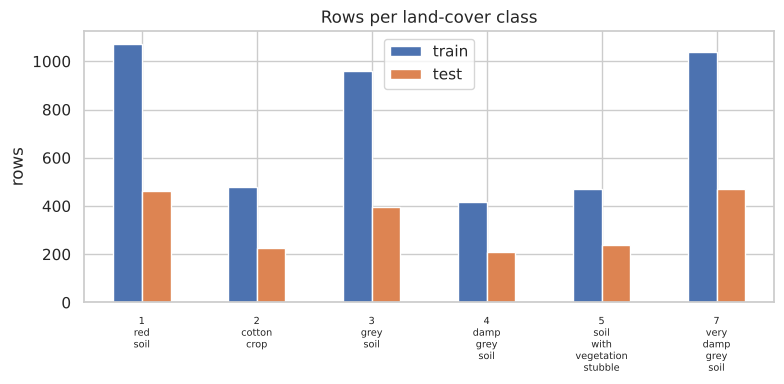

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
counts[["train", "test"]].plot(kind="bar", ax=ax)
ax.set_xticklabels([f"{k}\n" + v.replace(" ", "\n") for k, v in counts["class_name"].items()], rotation=0, fontsize=7)
ax.set_ylabel("rows")
ax.set_title("Rows per land-cover class")
plt.tight_layout()
plt.show()

## 3. Feature value ranges

In [6]:
X_train = train[feature_names()]
summary = X_train.describe().T[["min", "mean", "std", "max"]].round(1)
print("Overall min / max across all features:", X_train.values.min(), "/", X_train.values.max())
summary.head(8)

Overall min / max across all features: 27 / 157


,min,mean,std,max
top_left_band1,40.0,69.5,13.6,104.0
top_left_band2,27.0,83.9,22.7,137.0
top_left_band3,56.0,99.3,16.7,140.0
top_left_band4,33.0,82.6,18.7,154.0
top_mid_band1,40.0,69.2,13.6,102.0
top_mid_band2,27.0,83.5,22.8,137.0
top_mid_band3,50.0,99.2,16.6,145.0
top_mid_band4,29.0,82.5,18.7,157.0


All features are 8-bit pixel intensities (0-255), so they share a common scale. Scaling
still matters for distance-based and margin-based models (KNN, SVM, Logistic Regression),
so it will be applied in the preprocessing step.

## 4. Do the classes look separable? (central pixel)

In [7]:
centre_cols = [c for c in feature_names() if c.startswith("centre_")]
class_means = train.groupby(TARGET_COL)[centre_cols].mean().round(1)
class_means.index = [f"{i} - {CLASS_NAMES[i]}" for i in class_means.index]
class_means

,centre_band1,centre_band2,centre_band3,centre_band4
1 - red soil,62.8,95.3,108.1,88.6
2 - cotton crop,48.8,39.9,113.9,118.3
3 - grey soil,87.5,105.5,110.6,87.5
4 - damp grey soil,77.4,90.9,95.6,75.4
5 - soil with vegetation stubble,59.6,62.3,83.0,70.0
7 - very damp grey soil,69.0,77.4,81.6,64.1


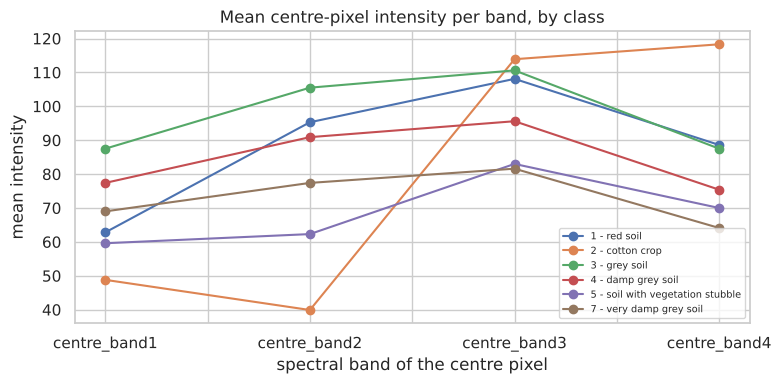

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
class_means.T.plot(kind="line", marker="o", ax=ax)
ax.set_ylabel("mean intensity")
ax.set_xlabel("spectral band of the centre pixel")
ax.set_title("Mean centre-pixel intensity per band, by class")
ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

## 5. Feature correlation

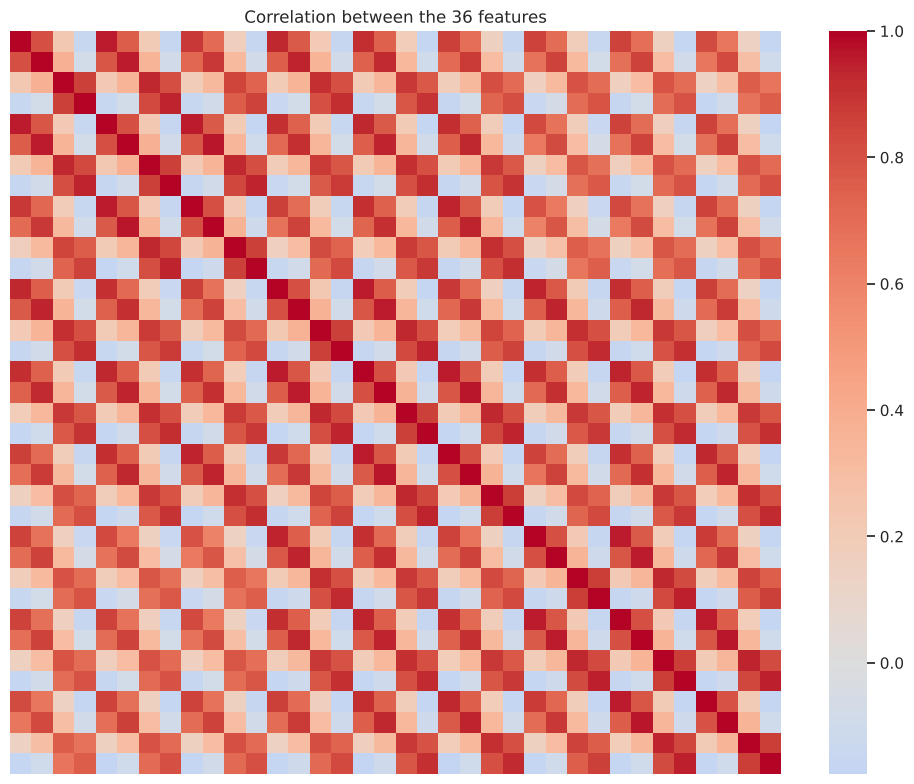

Highest pairwise correlation: 0.959
Share of feature pairs with |corr| > 0.9: 5.1 %


In [9]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=False, yticklabels=False)
ax.set_title("Correlation between the 36 features")
plt.tight_layout()
plt.show()

# Each pair of different features counted once (upper triangle, diagonal excluded)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Highest pairwise correlation:", round(pairs.max(), 3))
print("Share of feature pairs with |corr| > 0.9:",
      round(100 * (pairs.abs() > 0.9).mean(), 1), "%")

## 6. Summary of findings

- **Size and quality:** 4,435 training rows and 2,000 test rows, 36 integer features, no
  missing values and no duplicate rows. Observed values range from 27 to 157.
- **Classes:** 6 land-cover classes with moderate imbalance. In the training set the
  largest class is red soil (24.2%) and the smallest is damp grey soil (9.4%). Test class
  proportions are within about 2 percentage points of the training ones.
- **Separability:** the average centre-pixel profile differs clearly for some classes
  (for example cotton crop has a very low band 2 and the highest band 4). Damp grey soil
  and very damp grey soil have similar profile shapes, so they are the pair to watch in
  the confusion matrices later.
- **Correlation:** neighbouring pixels in the same band are strongly correlated (highest
  pairwise correlation 0.959, and 5.1% of feature pairs above 0.9). The features are far
  from independent, which is worth remembering when interpreting Naive Bayes.
- **Next step:** preprocessing (feature scaling fitted on the training data only) and the
  metrics helper.